# **Movie Dataset Python Assignment**


### **Question 1**
Dataset (`movie.csv`) ko pandas mein load karein aur uske pehle 5 rows display karein.

In [1]:
import pandas as pd


df = pd.read_csv('movie (1).csv')


df.head()

,Series_Title,Released_Year,Certificate,Runtime,Genre,IMDB_Rating,Meta_score,Director,Star1,No_of_Votes,Gross
0,The Shawshank Redemption,1994,A,142 min,Drama,9.3,80.0,Frank Darabont,Tim Robbins,2343110,28341469.0
1,The Godfather,1972,A,175 min,"Crime, Drama",9.2,100.0,Francis Ford Coppola,Marlon Brando,1620367,134966411.0
2,The Dark Knight,2008,UA,152 min,"Action, Crime, Drama",9.0,84.0,Christopher Nolan,Christian Bale,2303232,534858444.0
3,The Godfather: Part II,1974,A,202 min,"Crime, Drama",9.0,90.0,Francis Ford Coppola,Al Pacino,1129952,57300000.0
4,12 Angry Men,1957,U,96 min,"Crime, Drama",9.0,96.0,Sidney Lumet,Henry Fonda,689845,4360000.0


### **Question 2**
Dataset ka total shape (rows aur columns count) check karke print karein.

In [2]:
print("Shape of dataset (Rows, Columns):", df.shape)
print("Total Rows:", df.shape[0])
print("Total Columns:", df.shape[1])

Shape of dataset (Rows, Columns): (1000, 11)
Total Rows: 1000
Total Columns: 11


### **Question 3**
Check karein ki kis kis column mein missing values (null values) hain aur unka exact count kya hai.

In [3]:
missing_values = df.isnull().sum()
print(missing_values)

Series_Title       0
Released_Year      0
Certificate      101
Runtime            0
Genre              0
IMDB_Rating        0
Meta_score       157
Director           0
Star1              0
No_of_Votes        0
Gross            169
dtype: int64


### **Question 4**
Which movies were released after the year 2000? (Year 2000 ke baad release hone wali movies filter karein).

In [4]:

df['Released_Year_Num'] = pd.to_numeric(df['Released_Year'], errors='coerce')


movies_after_2000 = df[df['Released_Year_Num'] > 2000]
movies_after_2000[['Series_Title', 'Released_Year']]

,Series_Title,Released_Year
2,The Dark Knight,2008
5,The Lord of the Rings: The Return of the King,2003
8,Inception,2010
10,The Lord of the Rings: The Fellowship of the Ring,2001
13,The Lord of the Rings: The Two Towers,2002
...,...,...
947,Harry Potter and the Sorcerer's Stone,2001
948,The Others,2001
949,Blow,2001
950,Enemy at the Gates,2001


### **Question 5**
Which movies have an IMDB rating greater than 9? (9 se zyada IMDB rating wali movies display karein).

In [5]:
high_rated_movies = df[df['IMDB_Rating'] > 9.0]
high_rated_movies[['Series_Title', 'IMDB_Rating']]

,Series_Title,IMDB_Rating
0,The Shawshank Redemption,9.3
1,The Godfather,9.2


### **Question 6**
How many movies are there for each genre? (Har genre ki total kitni movies hain, count nikalye).

In [6]:
genre_counts = df['Genre'].value_counts()
genre_counts

Genre
Drama                        85
Drama, Romance               37
Comedy, Drama                35
Comedy, Drama, Romance       31
Action, Crime, Drama         30
                             ..
Action, Adventure, Family     1
Action, Crime, Mystery        1
Animation, Drama, Romance     1
Drama, War, Western           1
Adventure, Comedy, War        1
Name: count, Length: 202, dtype: int64

### **Question 7**
Which movies were directed by Christopher Nolan? (Christopher Nolan ki directed saari movies nikalye).

In [7]:
nolan_movies = df[df['Director'] == 'Christopher Nolan']
nolan_movies[['Series_Title', 'Released_Year', 'IMDB_Rating']]

,Series_Title,Released_Year,IMDB_Rating
2,The Dark Knight,2008,9.0
8,Inception,2010,8.8
21,Interstellar,2014,8.6
36,The Prestige,2006,8.5
63,The Dark Knight Rises,2012,8.4
69,Memento,2000,8.4
155,Batman Begins,2005,8.2
573,Dunkirk,2017,7.8


### **Question 8**
Which movies have 'Drama' mentioned in their genre? ('Drama' genre wali movies ko filter karein).

In [8]:
drama_movies = df[df['Genre'].str.contains('Drama', na=False)]
drama_movies[['Series_Title', 'Genre']].head()

,Series_Title,Genre
0,The Shawshank Redemption,Drama
1,The Godfather,"Crime, Drama"
2,The Dark Knight,"Action, Crime, Drama"
3,The Godfather: Part II,"Crime, Drama"
4,12 Angry Men,"Crime, Drama"


### **Question 9**
How can we sort all movies by IMDB rating in descending order? (Movies ko highest se lowest rating ke mutabiq sort karein).

In [9]:
sorted_by_rating = df.sort_values(by='IMDB_Rating', ascending=False)
sorted_by_rating[['Series_Title', 'IMDB_Rating']].head()

,Series_Title,IMDB_Rating
0,The Shawshank Redemption,9.3
1,The Godfather,9.2
2,The Dark Knight,9.0
3,The Godfather: Part II,9.0
4,12 Angry Men,9.0


### **Question 10**
How can we sort all movies by the number of votes they received? (No_of_Votes ke mutabiq descending order mein sort karein).

In [11]:
sorted_by_votes = df.sort_values(by='No_of_Votes', ascending=False)
sorted_by_votes[['Series_Title', 'No_of_Votes']].head()

,Series_Title,No_of_Votes
0,The Shawshank Redemption,2343110
2,The Dark Knight,2303232
8,Inception,2067042
9,Fight Club,1854740
6,Pulp Fiction,1826188


### **Question 11**
Which movie has the longest runtime? (Sabse lambi movie ka naam aur runtime minutes mein nikalye).

In [12]:

df['Runtime_mins'] = df['Runtime'].str.replace(' min', '').astype(int)


longest_movie = df.loc[df['Runtime_mins'].idxmax()]
print("Longest Movie:", longest_movie['Series_Title'])
print("Runtime (minutes):", longest_movie['Runtime_mins'])

Longest Movie: Gangs of Wasseypur
Runtime (minutes): 321


### **Question 12**
Which movies have Leonardo DiCaprio listed as the first star (Star1)?

In [13]:
dicaprio_movies = df[df['Star1'] == 'Leonardo DiCaprio']
dicaprio_movies[['Series_Title', 'Released_Year', 'Director']]

,Series_Title,Released_Year,Director
8,Inception,2010,Christopher Nolan
37,The Departed,2006,Martin Scorsese
145,Shutter Island,2010,Martin Scorsese
147,The Wolf of Wall Street,2013,Martin Scorsese
243,Catch Me If You Can,2002,Steven Spielberg
343,The Revenant,2015,Alejandro G. Iñárritu
361,Blood Diamond,2006,Edward Zwick
652,Titanic,1997,James Cameron
879,Once Upon a Time... in Hollywood,2019,Quentin Tarantino


### **Question 13**
What is the average IMDB rating of all movies? (Saari movies ki average rating calculate karein).

In [14]:
avg_imdb = df['IMDB_Rating'].mean()
print(f"Average IMDB Rating: {avg_imdb:.2f}")

Average IMDB Rating: 7.95


### **Question 14**
Dataset ka poora statistical summary (`describe()` function) display karein.

In [15]:
df.describe()

,IMDB_Rating,Meta_score,No_of_Votes,Gross,Released_Year_Num,Runtime_mins
count,1000.000000,843.000000,1.000000e+03,8.310000e+02,999.000000,1000.000000
mean,7.949300,77.971530,2.736929e+05,6.803475e+07,1991.217217,122.891000
std,0.275491,12.376099,3.273727e+05,1.097500e+08,23.297025,28.093671
min,7.600000,28.000000,2.508800e+04,1.305000e+03,1920.000000,45.000000
25%,7.700000,70.000000,5.552625e+04,3.253559e+06,1976.000000,103.000000
50%,7.900000,79.000000,1.385485e+05,2.353089e+07,1999.000000,119.000000
75%,8.100000,87.000000,3.741612e+05,8.075089e+07,2009.000000,137.000000
max,9.300000,100.000000,2.343110e+06,9.366622e+08,2020.000000,321.000000


### **Question 15**
'Runtime' column se 'min' text ko hata kar use proper integer (numeric) data type mein convert karein.

In [16]:
df.describe()

,IMDB_Rating,Meta_score,No_of_Votes,Gross,Released_Year_Num,Runtime_mins
count,1000.000000,843.000000,1.000000e+03,8.310000e+02,999.000000,1000.000000
mean,7.949300,77.971530,2.736929e+05,6.803475e+07,1991.217217,122.891000
std,0.275491,12.376099,3.273727e+05,1.097500e+08,23.297025,28.093671
min,7.600000,28.000000,2.508800e+04,1.305000e+03,1920.000000,45.000000
25%,7.700000,70.000000,5.552625e+04,3.253559e+06,1976.000000,103.000000
50%,7.900000,79.000000,1.385485e+05,2.353089e+07,1999.000000,119.000000
75%,8.100000,87.000000,3.741612e+05,8.075089e+07,2009.000000,137.000000
max,9.300000,100.000000,2.343110e+06,9.366622e+08,2020.000000,321.000000


### **Question 16**
'Gross' column mein jo missing values (NaN) hain, unko pooray column ke median value se fill (impute) karein.

In [18]:
gross_median = df['Gross'].median()
df['Gross'].fillna(gross_median, inplace=True)
print("Missing values in Gross after imputation:", df['Gross'].isnull().sum())

Missing values in Gross after imputation: 169


C:\Users\Bilal\AppData\Local\Temp\ipykernel_2332\3084092945.py:2: ChainedAssignmentError: A value is being set on a copy of a DataFrame or Series through chained assignment using an inplace method.
Such inplace method never works to update the original DataFrame or Series, because the intermediate object on which we are setting values always behaves as a copy (due to Copy-on-Write).

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' instead, to perform the operation inplace on the original object, or try to avoid an inplace operation using 'df[col] = df[col].method(value)'.

See the documentation for a more detailed explanation: https://pandas.pydata.org/pandas-docs/stable/user_guide/copy_on_write.html
  df['Gross'].fillna(gross_median, inplace=True)


### **Question 17**
Har 'Certificate' category mein total kitni movies hain? (Value counts nikalye).

In [19]:
certificate_counts = df['Certificate'].value_counts()
certificate_counts

Certificate
U           234
A           197
UA          175
R           146
PG-13        43
PG           37
Passed       34
G            12
Approved     11
TV-PG         3
GP            2
TV-14         1
16            1
TV-MA         1
Unrated       1
U/A           1
Name: count, dtype: int64

### **Question 18**
'IMDB_Rating' aur 'Meta_score' ke darmiyan correlation coefficient maloom karein.

In [20]:
correlation = df['IMDB_Rating'].corr(df['Meta_score'])
print(f"Correlation between IMDB_Rating and Meta_score: {correlation:.4f}")

Correlation between IMDB_Rating and Meta_score: 0.2685


### **Question 19**
Ek naya column banayein 'Rating_100_Scale' jisme 'IMDB_Rating' ko 10 se multiply kiya gaya ho.

In [21]:
df['Rating_100_Scale'] = df['IMDB_Rating'] * 10
df[['Series_Title', 'IMDB_Rating', 'Rating_100_Scale']].head()

,Series_Title,IMDB_Rating,Rating_100_Scale
0,The Shawshank Redemption,9.3,93.0
1,The Godfather,9.2,92.0
2,The Dark Knight,9.0,90.0
3,The Godfather: Part II,9.0,90.0
4,12 Angry Men,9.0,90.0


### **Question 20**
Year 1990 se 2000 (both inclusive) ke darmiyan release hone wali movies ki total count aur list nikaleyin.

In [22]:
df['Released_Year_Num'] = pd.to_numeric(df['Released_Year'], errors='coerce')
movies_90s = df[(df['Released_Year_Num'] >= 1990) & (df['Released_Year_Num'] <= 2000)]
print("Total Count:", len(movies_90s))
movies_90s[['Series_Title', 'Released_Year_Num']]

Total Count: 169


,Series_Title,Released_Year_Num
0,The Shawshank Redemption,1994.0
6,Pulp Fiction,1994.0
7,Schindler's List,1993.0
9,Fight Club,1999.0
11,Forrest Gump,1994.0
...,...,...
970,My Cousin Vinny,1992.0
971,Omohide poro poro,1991.0
972,Delicatessen,1991.0
973,Home Alone,1990.0


### **Question 21**
(Visualization) IMDB_Rating ka distribution dekhne ke liye ek neat Histogram plot karein.

Matplotlib is building the font cache; this may take a moment.


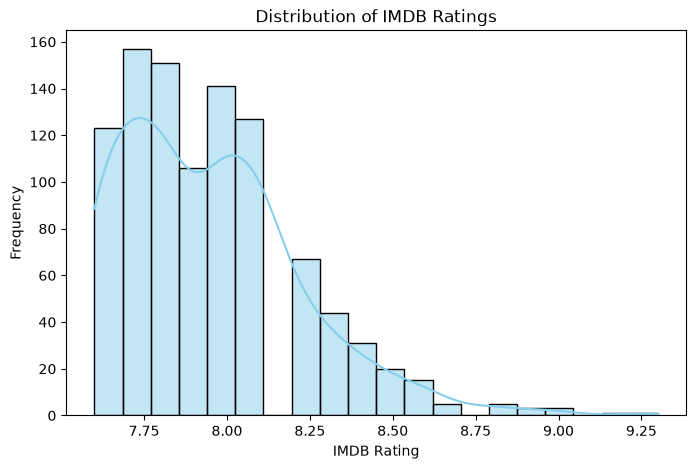

In [23]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8, 5))
sns.histplot(df['IMDB_Rating'], bins=20, kde=True, color='skyblue')
plt.title('Distribution of IMDB Ratings')
plt.xlabel('IMDB Rating')
plt.ylabel('Frequency')
plt.show()

### **Question 22**
(Visualization) Top 10 Directors aur unki total movies ka ek attractive Bar Chart banayein.

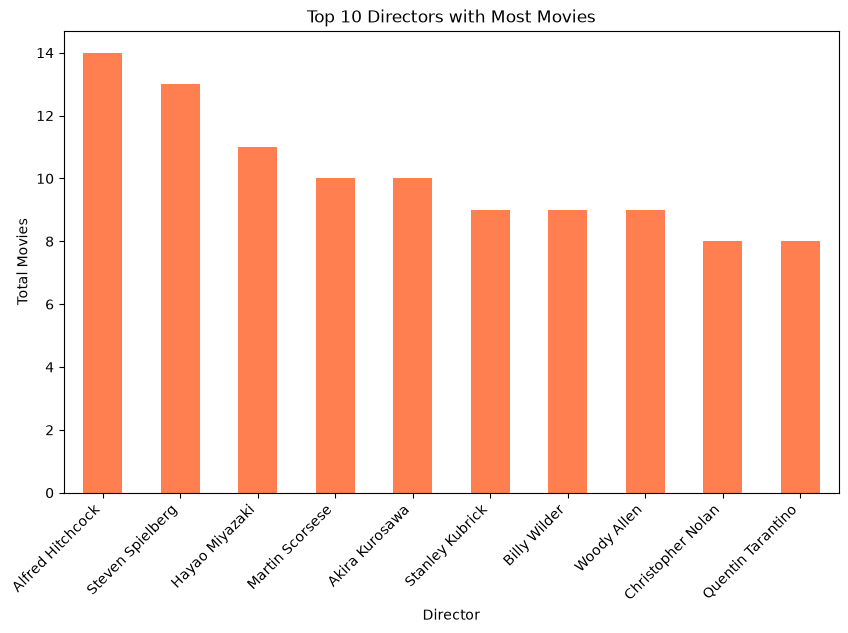

In [24]:
plt.figure(figsize=(10, 6))
top_directors = df['Director'].value_counts().head(10)
top_directors.plot(kind='bar', color='coral')
plt.title('Top 10 Directors with Most Movies')
plt.xlabel('Director')
plt.ylabel('Total Movies')
plt.xticks(rotation=45, ha='right')
plt.show()

### **Question 23**
(Visualization) IMDB_Rating aur Gross revenue ke darmiyan ek Scatter Plot banayein taake dono ka relation dikhe.

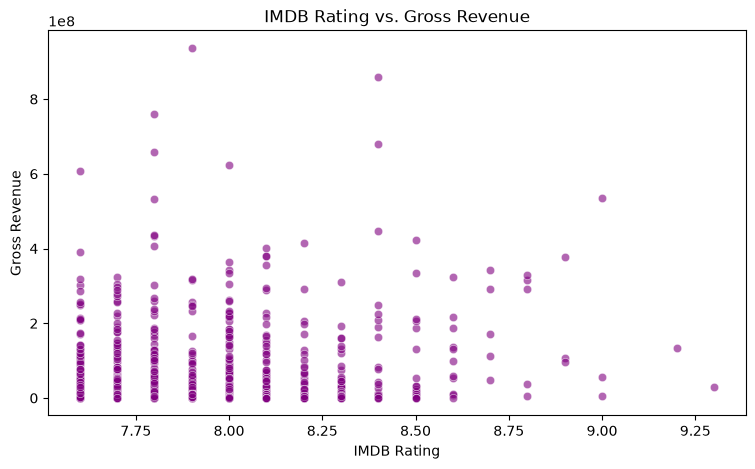

In [25]:
plt.figure(figsize=(9, 5))
sns.scatterplot(data=df, x='IMDB_Rating', y='Gross', alpha=0.6, color='purple')
plt.title('IMDB Rating vs. Gross Revenue')
plt.xlabel('IMDB Rating')
plt.ylabel('Gross Revenue')
plt.show()

### **Question 24**
(Visualization) Genres ka count dekhne ke liye top 5 genres ka ek clean Pie Chart banayein.

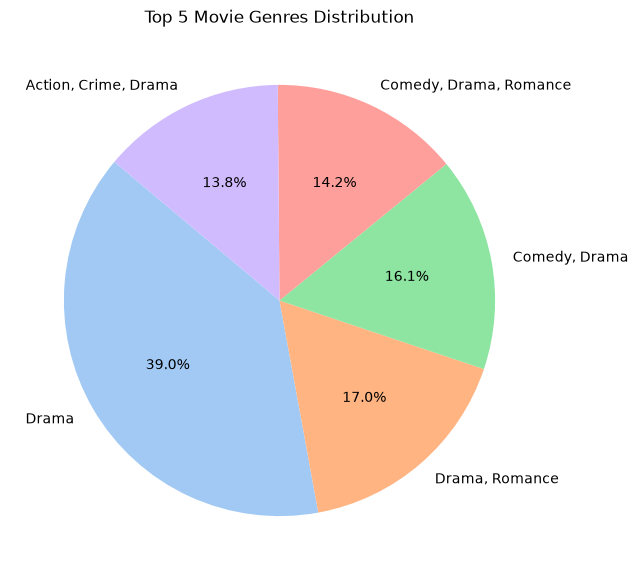

In [26]:
plt.figure(figsize=(7, 7))
top_genres = df['Genre'].value_counts().head(5)
plt.pie(top_genres, labels=top_genres.index, autopct='%1.1f%%', startangle=140, colors=sns.color_palette('pastel'))
plt.title('Top 5 Movie Genres Distribution')
plt.show()

### **Question 25**
(Visualization) Meta_score ka distribution aur outliers check karne ke liye ek Box Plot banayein.

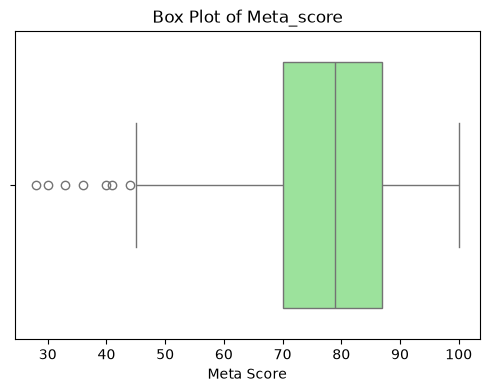

In [27]:
plt.figure(figsize=(6, 4))
sns.boxplot(x=df['Meta_score'], color='lightgreen')
plt.title('Box Plot of Meta_score')
plt.xlabel('Meta Score')
plt.show()

### **Question 26**
(Visualization) Dataset mein 'Certificate' wise average 'Gross' kamai ka ek Bar Plot banayein.

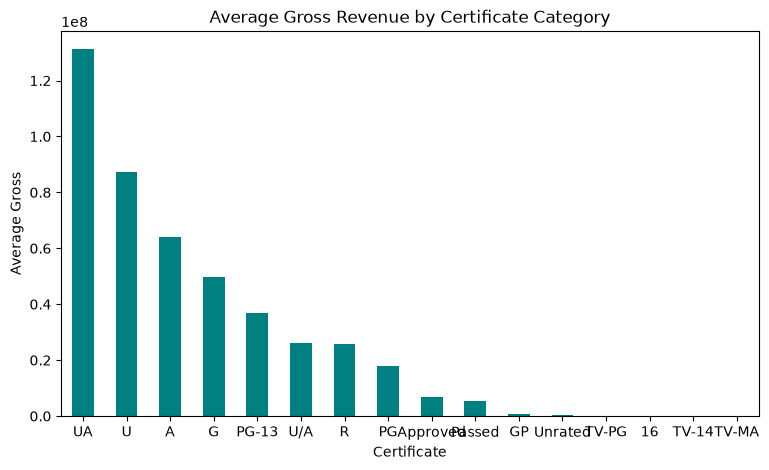

In [28]:
plt.figure(figsize=(9, 5))
cert_gross = df.groupby('Certificate')['Gross'].mean().sort_values(ascending=False)
cert_gross.plot(kind='bar', color='teal')
plt.title('Average Gross Revenue by Certificate Category')
plt.xlabel('Certificate')
plt.ylabel('Average Gross')
plt.xticks(rotation=0)
plt.show()

### **Question 27**
(Visualization) Har saal (Released_Year) kitni movies release hueen, iska ek Line Plot banayein.

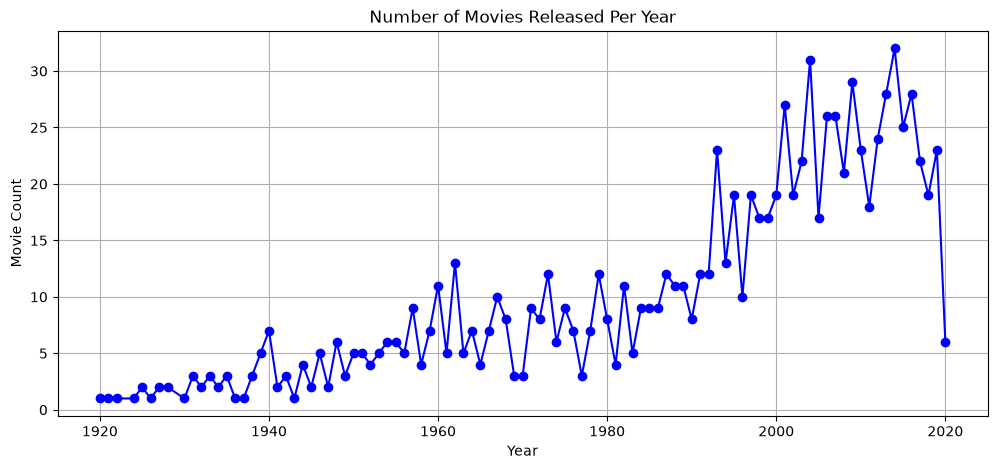

In [29]:
plt.figure(figsize=(12, 5))
year_counts = df['Released_Year_Num'].value_counts().sort_index()
year_counts.plot(kind='line', marker='o', color='b')
plt.title('Number of Movies Released Per Year')
plt.xlabel('Year')
plt.ylabel('Movie Count')
plt.grid(True)
plt.show()

### **Question 28**
(Visualization) 'No_of_Votes' ke mutabiq top 5 highest voted movies ka ek Horizontal Bar Chart banayein.

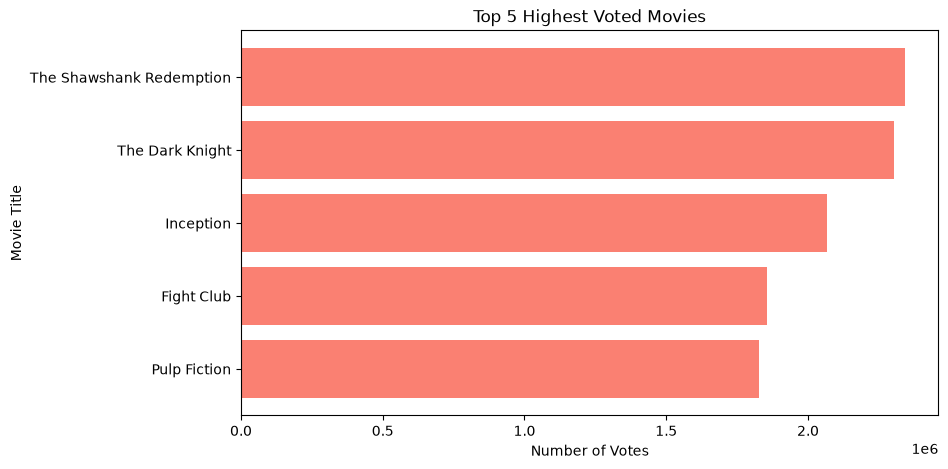

In [30]:
plt.figure(figsize=(9, 5))
top_voted = df.sort_values(by='No_of_Votes', ascending=False).head(5)
plt.barh(top_voted['Series_Title'][::-1], top_voted['No_of_Votes'][::-1], color='salmon')
plt.title('Top 5 Highest Voted Movies')
plt.xlabel('Number of Votes')
plt.ylabel('Movie Title')
plt.show()

### **Question 29**
Har movie ke 'Genre' column ko split karke check karein ki total unique genres pure dataset mein kitne hain.

In [31]:
all_genres = df['Genre'].dropna().str.split(',').sum()
unique_genres = set([genre.strip() for genre in all_genres])

print("Total Unique Genres:", len(unique_genres))
print("Unique Genres List:", unique_genres)

Total Unique Genres: 21
Unique Genres List: {'Biography', 'Comedy', 'Romance', 'Sport', 'Fantasy', 'Horror', 'Family', 'Musical', 'Music', 'Mystery', 'Animation', 'Action', 'Film-Noir', 'Western', 'Thriller', 'Sci-Fi', 'History', 'Crime', 'War', 'Adventure', 'Drama'}


### **Question 30**
Dataset ko poora clean karne ke baad safely ek nayi csv file 'cleaned_movies.csv' ke naam se save karein.

In [32]:
df.to_csv('cleaned_movies.csv', index=False)
print("Dataset successfully saved as 'cleaned_movies.csv'!")

Dataset successfully saved as 'cleaned_movies.csv'!


### **Question 31**
Kaunsi movies hain jinki 'IMDB_Rating' 8.5 se zyada hai AUR unka 'Gross' revenue 100 million (100,000,000) se zyada hai? (Dual condition filter)

In [33]:
df.to_csv('cleaned_movies.csv', index=False)
print("Dataset successfully saved as 'cleaned_movies.csv'!")

Dataset successfully saved as 'cleaned_movies.csv'!


### **Question 32**
Director 'Christopher Nolan' ki un movies ke naam aur release year nikalein jinka 'Runtime' 140 minutes se zyada hai.

In [34]:
nolan_long = df[(df['Director'] == 'Christopher Nolan') & (df['Runtime_mins'] > 140)]
nolan_long[['Series_Title', 'Released_Year', 'Runtime_mins']]

,Series_Title,Released_Year,Runtime_mins
2,The Dark Knight,2008,152
8,Inception,2010,148
21,Interstellar,2014,169
63,The Dark Knight Rises,2012,164


### **Question 33**
Aise actors (Star1) ki list nikalein jinhone 'Action' ya 'Sci-Fi' genre mein kaam kiya hai AUR unki movies ki 'IMDB_Rating' kam az kam 8.0 hai.

In [35]:
action_scifi_actors = df[
    (df['Genre'].str.contains('Action|Sci-Fi', na=False)) & 
    (df['IMDB_Rating'] >= 8.0)
]['Star1'].unique()

print(action_scifi_actors)

<ArrowStringArray>
[       'Christian Bale',           'Elijah Wood',     'Leonardo DiCaprio',
       'Lilly Wachowski',           'Mark Hamill',   'Matthew McConaughey',
       'Tatsuya Nakadai',        'Toshirô Mifune',         'Russell Crowe',
             'Jean Reno', 'Arnold Schwarzenegger',        'Michael J. Fox',
               'Pushkar',            'Aamir Khan',          'Peter Ramsey',
             'Joe Russo',          'Choi Min-sik',          'Yôji Matsuda',
         'Harrison Ford',      'Sigourney Weaver',            'Jim Carrey',
      'Malcolm McDowell',           'Keir Dullea',         'Brigitte Helm',
         'Vicky Kaushal',                  'Yash',               'Prabhas',
        'Manoj Bajpayee',           'Irrfan Khan',             'Tom Hardy',
          'Hugo Weaving',          'Akshay Kumar',         'Jason Flemyng',
          'Bruce Willis',      'Alisa Freyndlikh',         'Sanjeev Kumar',
         'Buster Keaton',         'Shahid Kapoor',          'Hugh Jac

### **Question 34**
Year 2010 se 2020 ke darmiyan release hone wali un movies ka data filter karein jinko Certificate 'UA' ya 'A' mila hai.

In [36]:
filtered_ua_a = df[
    (df['Released_Year_Num'] >= 2010) & 
    (df['Released_Year_Num'] <= 2020) & 
    (df['Certificate'].isin(['UA', 'A']))
]
filtered_ua_a[['Series_Title', 'Released_Year_Num', 'Certificate']]

,Series_Title,Released_Year_Num,Certificate
8,Inception,2010.0,UA
19,Gisaengchung,2019.0,A
21,Interstellar,2014.0,UA
33,Joker,2019.0,A
34,Whiplash,2014.0,A
...,...,...,...
898,Dawn of the Planet of the Apes,2014.0,UA
900,Serbuan maut,2011.0,A
901,End of Watch,2012.0,A
903,A Star Is Born,2018.0,UA


### **Question 35**
Dataset mein 'Meta_score' 90 se zyada aur 'IMDB_Rating' 8.5 se kam wali unique movies kaunsi hain?

In [37]:
meta_imdb_diff = df[(df['Meta_score'] > 90) & (df['IMDB_Rating'] < 8.5)]
meta_imdb_diff[['Series_Title', 'Meta_score', 'IMDB_Rating']]

,Series_Title,Meta_score,IMDB_Rating
66,WALL·E,95.0,8.4
74,Apocalypse Now,94.0,8.4
78,Dr. Strangelove or: How I Learned to Stop Worr...,97.0,8.4
81,Rear Window,100.0,8.4
89,Jodaeiye Nader az Simin,95.0,8.3
...,...,...,...
875,Fantasia,96.0,7.7
881,The Florida Project,92.0,7.6
895,Leviafan,92.0,7.6
994,A Hard Day's Night,96.0,7.6


### **Question 36**
(Visualization) 'Drama' aur 'Action' genres ki movies ke 'Gross' revenue ko compare karne ke liye ek Grouped Box Plot ya Violin Plot banayein.

C:\Users\Bilal\AppData\Local\Temp\ipykernel_2332\469182929.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=drama_action[drama_action['Genre'].isin(['Drama', 'Action'])], x='Genre', y='Gross', palette='Set2')


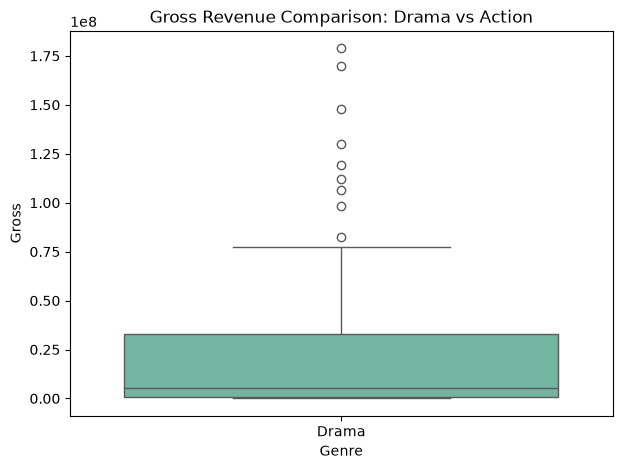

In [38]:
drama_action = df[df['Genre'].str.contains('Drama|Action', na=False)]
plt.figure(figsize=(7, 5))
sns.boxplot(data=drama_action[drama_action['Genre'].isin(['Drama', 'Action'])], x='Genre', y='Gross', palette='Set2')
plt.title('Gross Revenue Comparison: Drama vs Action')
plt.show()

### **Question 37**
Har Director ki un movies ka count maloom karein jinhone 'No_of_Votes' 500,000 (5 lakh) se zyada hasil kiye hain.

In [39]:
high_votes_df = df[df['No_of_Votes'] > 500000]
director_vote_counts = high_votes_df['Director'].value_counts()
director_vote_counts.head(10)

Director
Christopher Nolan    8
Quentin Tarantino    8
Steven Spielberg     8
Peter Jackson        5
David Fincher        5
Martin Scorsese      5
James Cameron        5
Ridley Scott         4
Anthony Russo        4
Stanley Kubrick      4
Name: count, dtype: int64

### **Question 38**
Un movies ke naam aur ratings batayein jinka 'Released_Year' 2000 se pehle ka hai AUR unka 'Gross' unke overall median gross se zyada hai.

In [40]:
median_gross = df['Gross'].median()
classic_high_gross = df[(df['Released_Year_Num'] < 2000) & (df['Gross'] > median_gross)]
classic_high_gross[['Series_Title', 'Released_Year_Num', 'Gross']]

,Series_Title,Released_Year_Num,Gross
0,The Shawshank Redemption,1994.0,28341469.0
1,The Godfather,1972.0,134966411.0
3,The Godfather: Part II,1974.0,57300000.0
6,Pulp Fiction,1994.0,107928762.0
7,Schindler's List,1993.0,96898818.0
...,...,...,...
985,Escape from Alcatraz,1979.0,43000000.0
987,Midnight Express,1978.0,35000000.0
988,Close Encounters of the Third Kind,1977.0,132088635.0
992,The Jungle Book,1967.0,141843612.0


### **Question 39**
Aisi movies ka data nikalein jahan 'Star1' (Main Actor) aur 'Director' dono bilkul same person hain.

In [41]:
same_person = df[df['Star1'] == df['Director']]
same_person[['Series_Title', 'Director', 'Star1']]

,Series_Title,Director,Star1
26,La vita è bella,Roberto Benigni,Roberto Benigni
51,Modern Times,Charles Chaplin,Charles Chaplin
52,City Lights,Charles Chaplin,Charles Chaplin
83,The Great Dictator,Charles Chaplin,Charles Chaplin
102,Braveheart,Mel Gibson,Mel Gibson
124,Citizen Kane,Orson Welles,Orson Welles
127,The Kid,Charles Chaplin,Charles Chaplin
167,Unforgiven,Clint Eastwood,Clint Eastwood
193,The Gold Rush,Charles Chaplin,Charles Chaplin
194,Sherlock Jr.,Buster Keaton,Buster Keaton


### **Question 40**
(Visualization) Top 5 highest rated movies aur unke 'Meta_score' vs 'IMDB_Rating' (scaled to 100) ka ek Side-by-Side Comparison Bar Chart banayein.

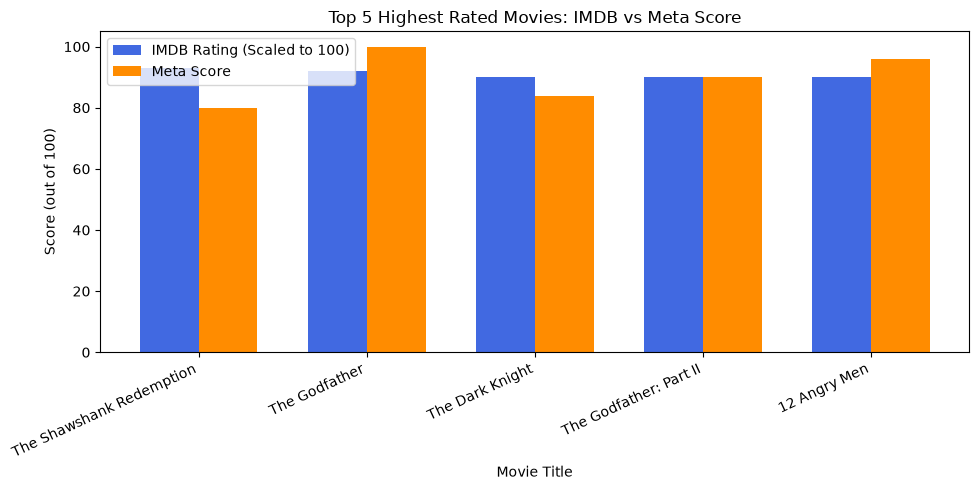

In [42]:
top_5_movies = df.sort_values(by='IMDB_Rating', ascending=False).head(5)

import numpy as np
x = np.arange(len(top_5_movies['Series_Title']))
width = 0.35

plt.figure(figsize=(10, 5))
plt.bar(x - width/2, top_5_movies['IMDB_Rating'] * 10, width, label='IMDB Rating (Scaled to 100)', color='royalblue')
plt.bar(x + width/2, top_5_movies['Meta_score'], width, label='Meta Score', color='darkorange')

plt.xlabel('Movie Title')
plt.ylabel('Score (out of 100)')
plt.title('Top 5 Highest Rated Movies: IMDB vs Meta Score')
plt.xticks(x, top_5_movies['Series_Title'], rotation=25, ha='right')
plt.legend()
plt.tight_layout()
plt.show()